## Part 1: Iterative solver for the area-Mach relation and analyses of Space Shuttle Main Engine

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Defining the gas properties and constants

In [2]:


# Model assumptions: steady, quasi 1-D, axisymmetric flow
# The gas is calorically perfect, with constant gamma and R
# Flow is isentropic except across the modeled adiabatic normal shock
# Calculations use SI units: input and output conversions are explicit

# Universal constants
Ru = 8314.462618        # J/(kmol*K)
g0 = 9.80665            # m/s^2

# Gas properties from assignment
gamma = 1.2
MW = 22.0               # kg/kmol

# The specific gas constant is obtained from R = Ru/MW
R = Ru / MW
# cp is calculated assuming a calorically perfect gas
cp = gamma * R / (gamma - 1)

print(f"R = {R:.3f} J/(kg*K)")
print(f"cp = {cp:.3f} J/(kg*K)")

R = 377.930 J/(kg*K)
cp = 2267.581 J/(kg*K)


Everything works! Let's now add the part 1 conditions.


In [3]:
# Part 1 stagnation/design conditions
P0_part1 = 20.4e6       # Pa
T0_part1 = 3500.0       # K
pe_design = 18.4592e3   # Pa

At = 0.30               # m^2

# These values remain constatn for the isentropic nozzle analysis

We will now enter the SSME-shaped nozzle coordinates

In [4]:
x_cm = np.array([0.0, 10.1, 20.2, 30.3, 40.4, 50.5, 63.1, 75.7,
                126.1, 176.6, 227.0, 252.3, 302.7, 353.2, 403.6, 
                454.1, 504.5, 555.0, 605.4, 655.9, 706.3, 756.8, 
                769.4])

r_cm = np.array([44.15, 39.10, 32.79, 30.90, 32.79, 39.10, 46.67, 55.50,
                83.25, 104.69, 127.39, 137.48, 153.88, 171.54, 187.93,
                203.07, 216.94, 229.56, 244.69, 254.78, 264.87, 271.18, 
                272.06])

# convert cm to m
x = x_cm / 100
r = r_cm / 100

# Cross-sectional area
A = np.pi * r**2

# Area ratio using throat area
AR = A / At

with this information we can now look for the minimum area

In [5]:
throat_index = np.argmin(A)

print("Throat index:", throat_index)
print("Throat x:", x[throat_index], "m")
print("Calculated throat area:", A[throat_index], "m^2")
print("Exit area:", A[-1], "m^2")
print("Exit area ratio:", A[-1] / At)

Throat index: 3
Throat x: 0.303 m
Calculated throat area: 0.29996240815740705 m^2
Exit area: 23.2530143777134 m^2
Exit area ratio: 77.51004792571133


Double checking to make sure the geometry looks right

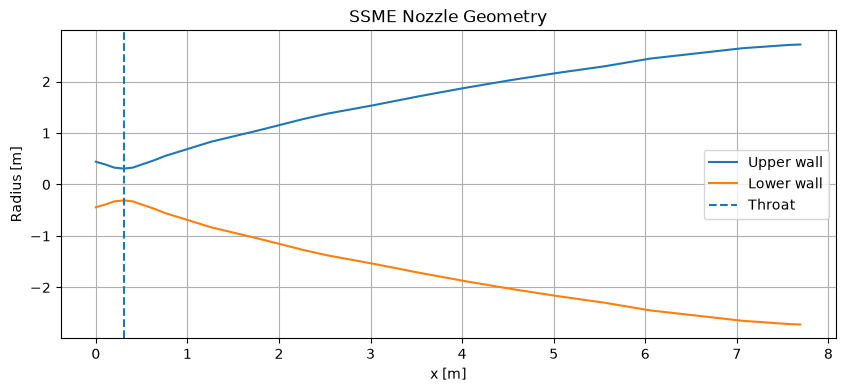

In [6]:
plt.figure(figsize=(10,4))

plt.plot(x, r, label="Upper wall")
plt.plot(x, -r, label="Lower wall")

plt.axvline(x[throat_index], linestyle="--", label="Throat")

plt.xlabel("x [m]")
plt.ylabel("Radius [m]")
plt.title("SSME Nozzle Geometry")
plt.grid(True)
plt.legend()

plt.show()

Everything looks right now it's time to start the Area-Mach equation

In [7]:
def area_mach(M, gamma):
    """
    Returns A/A* for a given Mach number M and gamma
    """

    exponent = (gamma + 1) / (2 * (gamma -1))

    bracket = (
        2 / (gamma + 1)
        * (1 + (gamma - 1) / 2 * M **2)
    )

    return (1 / M) * bracket**exponent

In [8]:
print(area_mach(1.0, gamma))

1.0


this equation returning to 1 is good since it means M = 1 interchangeably with A / A* = 1

Now we can set up the Newton function and solve for
$$F(M)=0$$

where 
$$ F(M)=\frac{A}{A^*}_{calculated}-\frac{A}{A^*}_{target} $$

From class, we learned 
$$M_{j+1}=M_j-\frac{F(M_j)}{F'(M_j)}$$

with $F(M_j)$ and $F'(M_j)$ being

$$F(M)=\frac{1}{M}\Bigl[\frac{2}{\gamma+1}(1+\frac{\gamma-1}{2}M^2)\Bigr]^{\frac{\gamma+1}{2(\gamma-1)}}-\frac{A}{A*}$$
and

$$F'(M)=\frac{2(M^2-1)}{(\gamma+1)M^2}\Bigl[\frac{2}{\gamma+1}(1+\frac{\gamma-1}{2}M^2)\Bigr]^{\frac{3-\gamma}{2(\gamma-1)}} $$

I split the huge Newton's iteration into subsitution with 
$$H(M)= \frac{2}{\gamma+1}(1+\frac{\gamma-1}{2}M^2) $$

$$H'=\frac{2(\gamma -1)}{\gamma+1}M $$

and
$$n=\frac{\gamma+1}{2(\gamma-1)}$$

to create

$$F(M)= \frac{H^n}{M}-AR $$

and

$$F'(M)=\frac{nH^{n-1}H'}{M}-\frac{H^n}{M^2}$$

In [9]:
def area_mach_residual(M, AR_target, gamma):
    """
    F(M) = calculated area ratio - target area ratio
    """

    H = (
        2 / (gamma + 1)
        * (1 + (gamma - 1) / 2* M**2)
    )

    n = (gamma + 1) / (2 * (gamma -1))

    return H**n / M - AR_target

The derivatie portion:

In [10]:
def area_mach_derivative(M, gamma):
    """
    dF/dM for the area-Mach residual
    """

    H = (
            2 / (gamma + 1)
            * (1 + (gamma - 1) / 2* M**2)
        )
    
    n = (gamma + 1) / (2 * (gamma -1))

    H_prime = (
        2 * (gamma - 1) / (gamma + 1) * M
    )

    return (
        n * H**(n-1) * H_prime / M - H**n / M**2
    )

With Newton's method equation written into the code, we can now utilize it

In [11]:
def solve_mach_from_area(AR_target, gamma, branch="supersonic", 
                         tol=1e-10, max_iter=100):
    """
    Solve the isentropic area-Mach relation using Newton's method
     
    AR_target is the prescribed dimensionless area ratio A/A*.
    branch selects the subsonic or supersonic root.
    tol is the absoolute tolerance on the chance in Mach number.
    max_iter limits the number of Newton updates
    """

    if AR_target < 1:
        raise ValueError("A/A* cannot be less than 1.")

    # Handle the sonic solution directly because dF/dM is zero at M = 1
    if abs(AR_target - 1.0) < tol:
        return 1.0

    # Inital guess
    if branch == "subsonic":
        M = 0.01
    elif branch == "supersonic":
        M = 3.0
    else:
        raise ValueError("branch must be 'subsonic' or 'supersonic'")

    for iteration in range(max_iter):

        F = area_mach_residual(M, AR_target, gamma)
        dF = area_mach_derivative(M, gamma)

        M_new = M - F / dF

        # Keep Newton on requested branch
        if branch =="subsonic":
            if M_new <= 0:
                M_new = M / 2
            elif M_new >= 1:
                M_new = (M + 1) / 2
        elif branch == "supersonic":
            if M_new <= 1:
                M_new = (M + 1) / 2

        if abs(M_new - M) < tol:
            return M_new
        
        M = M_new

    raise RuntimeError("Newton solver did not converge")

Let's test it before we feed info into it

In [12]:
#sonic conditions
print(solve_mach_from_area(1.0, gamma))

1.0


As expected, the M = 1 \
Let's move on to the exit area ratio

In [13]:
AR_exit = AR[-1]

M_exit_sup = solve_mach_from_area(
    AR_exit,
    gamma,
    branch="supersonic"
)

M_exit_sub = solve_mach_from_area(
    AR_exit,
    gamma,
    branch="subsonic"
)

print("Supersonic exit Mach:", M_exit_sup)
print("Subsonic exit Mach:", M_exit_sub)

Supersonic exit Mach: 4.706723375059314
Subsonic exit Mach: 0.007638290337089968


In [14]:
# Part 1: Mach number distribution along the nozzle

M = np.empty_like(AR)

for i in range(len(AR)):
    if i < throat_index:
        M[i] = solve_mach_from_area(AR[i], gamma, branch="subsonic")

    elif i == throat_index:
        # The rounded throat radus gives A/At slightly below 1
        # Enfore the exact sonic condition at the assigned choked throat
        M[i] = 1.0

    else:
        M[i] = solve_mach_from_area(AR[i], gamma, branch="supersonic")

# Static temperature and pressure at every nozzle station

factor = 1 + (gamma - 1) / 2 * M**2

T = T0_part1 / factor

P = P0_part1 / factor**(gamma / (gamma - 1))

# Check the exit conditions

print(f"Throat Mach number: {M[throat_index]:.6f}")
print(f"Exit Mach number: {M[-1]:.6f}")
print(f"Exit temperature: {T[-1]:.2f} K")
print(f"Exit pressure: {P[-1] / 1000:.4f} kPa")

Throat Mach number: 1.000000
Exit Mach number: 4.706723
Exit temperature: 1088.54 K
Exit pressure: 18.4621 kPa


The pressure is within about 0.016% of the assigned desgin pressure, 18.4592 kPa, consistent with the small differences between the supplied contour and stated areas.

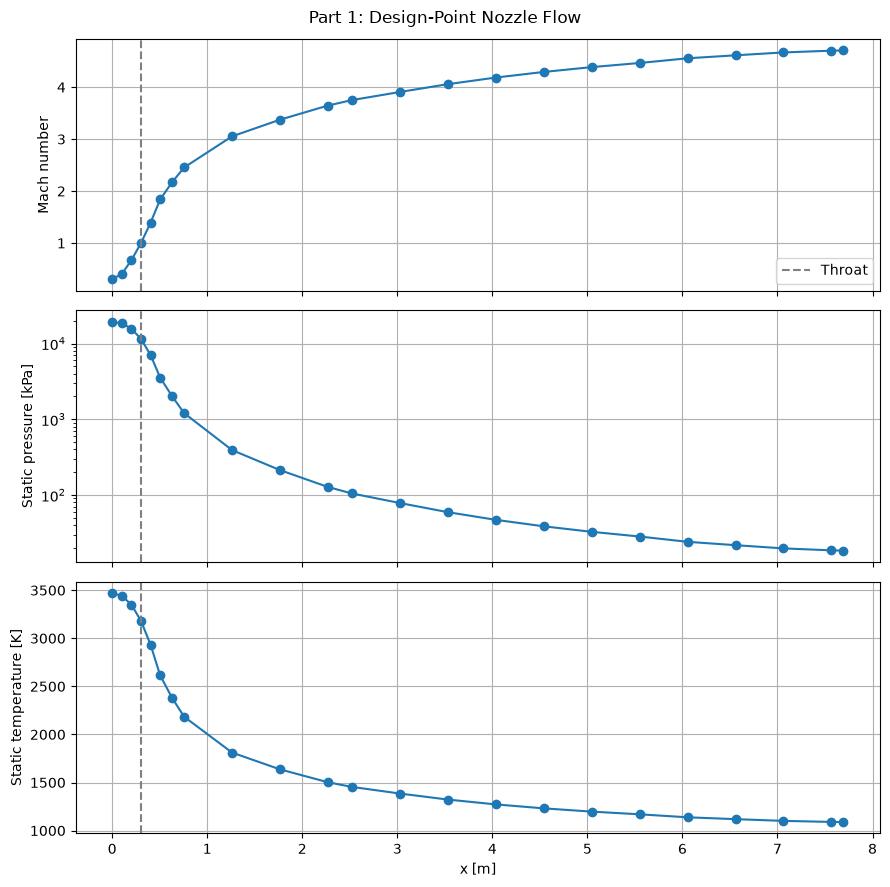

In [15]:
fig, axes = plt.subplots(
    3, 1, figsize=(9, 9), sharex=True
)

for ax, values, label in zip(
    axes, [M, P / 1000, T],
    ["Mach number", "Static pressure [kPa]", 
     "Static temperature [K]"]
 ):
    ax.plot(x, values, "o-")
    ax.axvline(
        x[throat_index],
        color="grey",
        linestyle="--",
        label="Throat"
    )
    ax.set_ylabel(label)
    ax.grid(True)

axes[0].legend()
axes[-1].set_xlabel("x [m]")

fig.suptitle("Part 1: Design-Point Nozzle Flow")
axes[1].set_yscale("log")
fig.tight_layout()
plt.show()

We'll finish this part 1 by calculating mass flow, exit velocity, vacuum thrust, ann specific impulse

We will calculate the mass flow throufh the choked throat
For M = 1 at the throat,
$$\dot{m}= \frac{P_0A_t}{\sqrt{T_0}}\sqrt{\frac{\gamma}{R}}\left(\frac{2}{\gamma+1}\right)^{\frac{\gamma+1}{2(\gamma-1)}}

In [16]:
# Part 1: Mass flow through the choked throat

mdot_part1 = (
    P0_part1 * At / np.sqrt(T0_part1)
    * np.sqrt(gamma / R)
    * (2 / (gamma + 1)) ** (
        (gamma + 1) / (2 * (gamma - 1)))
)

print(f"Mass flow: {mdot_part1:.2f} kg/s")

Mass flow: 3450.98 kg/s


Next we will calculate exit velocity. We know Mach number realtes velocity to the local s0eed of sound:
$$V_e=M_ea_e, \qquad a_e=\sqrt{\gamma RT_e}$$

which we will use our previous entries for M and T

In [17]:
# Part 1: Exit speed of sound and flow velocity

a_exit_part1 = np.sqrt(gamma * R * T[-1])

Ve_part1 = M[-1] * a_exit_part1

print(f"Exit speed of sound: {a_exit_part1:.2f} m/s")
print(f"Exit flow velocity: {Ve_part1:.2f} m/s")

Exit speed of sound: 702.62 m/s
Exit flow velocity: 3307.02 m/s


Next we will calcualte the vacuum thrust using the following equation
$$F = \dot{m}V_e + (p_e-p_{\infty})A_e$$
where the first term is the momentum thrust and the second term is pressure thrust. Now in a vacuum, $p_\infty$ is 0

In [18]:
# Part 1: Vacuum thrust

Ae = A[-1]              # Exit area [m^2]
p_ambient = 0.0         # Vacuum pressure [Pa]

F_momentum_part1 = mdot_part1 * Ve_part1
F_pressure_part1 = ((P[-1] - p_ambient) * Ae)

F_vac_part1 = F_momentum_part1 + F_pressure_part1

print(f"Momentum thrust: {F_momentum_part1 / 1000:.2f} kN")
print(f"Pressure thrust: {F_pressure_part1 / 1000:.2f} kN")
print(f"Total vacuum thrust: {F_vac_part1 / 1000:.2f} kN")

Momentum thrust: 11412.46 kN
Pressure thrust: 429.30 kN
Total vacuum thrust: 11841.76 kN


Now let's obtain vacuum specific impulse. Specific impuls emeasures thrust per unit propellant weight flow:
$$I_{sp}=\frac{F}{\dot{m}g_0}$$

In [19]:
# Part 1: Vacuum specific impulse

Isp_vac_part1 = F_vac_part1 / (mdot_part1 * g0)

print(f"vacuum specific impulse: {Isp_vac_part1:.2f} s")

vacuum specific impulse: 349.91 s


In part 1, our perfrmance results should therefore be:
a &emsp; a

Quantity &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; Result
___
Mass flow &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; 3,450.98 kg/s\
Exit velocity &nbsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; 3,307.02 m/s\
Vacuum thrust &nbsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; &emsp; 11,841.76 kN\
Vacuum specific impulse &emsp; &emsp; &emsp; &emsp; 349.91 s

## Part 2: Same nozzle, run off-design

First we need to calcualte the ideal isentropic basline at the new chamber condition. Then we'll use the Pitot measuremnet to investigate the shock. The assignments gave us values we will insert into code.

In [20]:
# Part 2: Operating conditions and gemoetry
atm_to_Pa = 101325.0

P01_part2 = 10.0 * atm_to_Pa        # Chamber stagnation pressure [Pa]
T0_part2 = 2000.0                   # Stagnation temperature[K]

P_pitot_measured = 0.5 * atm_to_Pa  # Measured stagnation pressure [Pa]

Ae_part2 = 23.256                   # assigned exxit area [m^2]
AR_exit_part2 = Ae_part2 / At

p_sea_level = atm_to_Pa
p_vacuum = 0.0

with the new assgined exit area 23.256 M^2 and the same gas properties from part 1, we will now calculate the ideal isentropic exit state

In [21]:
# Part 2: Ideal isentropic exit conditions

Me_part2_iso = solve_mach_from_area(
    AR_exit_part2,
    gamma,
    branch="supersonic")

factor_exit_part2 = 1 + (gamma - 1) / 2 * Me_part2_iso**2

Te_part2_iso = T0_part2 / factor_exit_part2

pe_part2_iso = P01_part2 / factor_exit_part2**(gamma / (gamma - 1))

Ve_part2_iso = Me_part2_iso * np.sqrt(gamma * R * Te_part2_iso)

print(f"Ideal exit Mach: {Me_part2_iso:.6f}")
print(f"Ideal exit emperature: {Te_part2_iso:.2f} K")
print(f"Ideal exit pressure: {pe_part2_iso / 1000:.6f} kPa")
print(f"Ideal exit velocity: {Ve_part2_iso:.2f} m/s")

Ideal exit Mach: 4.706815
Ideal exit emperature: 622.00 K
Ideal exit pressure: 0.916849 kPa
Ideal exit velocity: 2499.89 m/s


The exit Mach is similar to that of the oen from Part 1. This is because the area ratio and $\gamma$ determine the isentropic Mach solution. Changeing the chamber pressure and temperature changes the exit pressure, temperature, and velocity. 

So let's now calcualte the choked mass flow

In [22]:
# Part 2: Mass flow throuh the choked throat

mdot_part2 = (
    P01_part2 * At / np.sqrt(T0_part2)
    * np.sqrt(gamma / R)
    * (2 / (gamma + 1))**(
        (gamma + 1) / (2 * (gamma -1))
    )
)

print(f"Part 2 mass flow: {mdot_part2:.2f} kg/s")

Part 2 mass flow: 226.75 kg/s


We will use this mass flow for the embedded-shock model, asusming the throat remains choked

So next we will calculate the ideal comparison thrust and specific impulse using the thrust equation used previously

In [23]:
# Part 2: Ideal isentropic performance

# Formal ambient-pressure comparison: the computed exit state is held fixed
# Changing back pressure in an actual nozzle can cahnge the internal flow
# Interpret these thrust and Isp values together with that limitation
F_momentum_part2_iso = mdot_part2 * Ve_part2_iso

F_vac_part2_iso = (
    F_momentum_part2_iso
    + (pe_part2_iso - p_vacuum) * Ae_part2
)

F_sl_part2_iso = (
    F_momentum_part2_iso
    + (pe_part2_iso - p_sea_level) * Ae_part2
)

Isp_vac_part2_iso = (
    F_vac_part2_iso / (mdot_part2 * g0)
)

Isp_sl_part2_iso = (
    F_sl_part2_iso / (mdot_part2 * g0)
)

print(f"Ideal momentum thrust: {F_momentum_part2_iso / 1000:.2f} kN")
print(f"Ideal vacuum thrust: {F_vac_part2_iso / 1000:.2f} kN")
print(f"Ideal sea-level thrust: {F_sl_part2_iso / 1000:.2f} kN")
print(f"Ideal vacuum Isp: {Isp_vac_part2_iso:.2f} s")
print(f"Ideal sea-level Isp: {Isp_sl_part2_iso:.2f} s")

Ideal momentum thrust: 566.85 kN
Ideal vacuum thrust: 588.17 kN
Ideal sea-level thrust: -1768.24 kN
Ideal vacuum Isp: 264.51 s
Ideal sea-level Isp: -795.19 s


The negative sea-level result is the formal result of the imposed isentropic model. Its exit pressure is only 0.917 kPa, compared with atmospheric pressure of 101.325 kPa so the pressure-thrust term overwhelms the momentum term. Real flow can develop shcoks and separationl; this ideal calculation does not establish teh actual sea-level operating state.

With this, we will calculate what a pitot probe would read behind a normal shock in the ideal exhaust and compare it with the measured 0.5 atm

We first havbe to degine the normal-shock stagnation-pressure relation.
For a nr=ormal shock,

$$\frac{P_{02}}{P_{01}}=\left[\frac{(\gamma +1)M_1^2}{(\gamma-1)M_1^2+2}\right]^{\frac{\gamma}{\gamma-1}}

\left[\frac{\gamma+1}{2\gamma M_1^2-(\gamma-1)}\right]^{\frac{1}{\gamma-1}}$$

Where $M_1$ is the Mach number immediately before the shock. The shcok causes a loss of stagnation pressure

In [24]:
# Stagnation-pressure ratio across a normal shock

def normal_shock_p0_ratio(M1, gamma):
    """
    Returns downstream/upstream stagnationpressure: P02/P01.
    """
    term1 = (
        (gamma + 1) * M1**2
        / ((gamma - 1) * M1**2 + 2)
    )

    term2 = (
        (gamma + 1)
        / (2 * gamma * M1**2 - (gamma - 1))
    )


    return (
        term1**(gamma / (gamma - 1))
        * term2**(1 / (gamma -1))
    )

Now with that equation defined, we will predict the Pitot reading for the ideal exhaust. A Pitot probe facing supersonic flow has a shock ahead of it. For our ideal exhaust prediction, the upstream Mach is Me_part2_iso

In [25]:
# Predicted Pitot reading for the ideal super sonic exhaust

p0_ratio_probe = normal_shock_p0_ratio(
    Me_part2_iso, gamma
)

P_pitot_predicted = P01_part2 * p0_ratio_probe

print(f"Predicted Pitot pressure: {P_pitot_predicted / atm_to_Pa:.6f} atm")
print(f"Measured Pitot pressure: {P_pitot_measured / atm_to_Pa:.6f} atm")

Predicted Pitot pressure: 0.234224 atm
Measured Pitot pressure: 0.500000 atm


We'll now test the given embedded normal-shock model. Under that model, the flow downstream of the interal shock is subsonic, and the Pitot measurement givces its stagnation pressure, therefore,
$$\frac{P_{02}}{P_{01}}=\frac{0.5}{10}=0.05$$

We will now use Newton's method to find the Mach number ahead of the embedded shock. The residual is
$$G(M_1)=\left(\frac{P_{02}}{P_{01}}\right)_{calculated}-0.05$$

and we seek $G(M_1)=0$ using,

$$ M_{1,j+1}=M_{1,j}-\frac{G(M_{1,j})}{G'(M_{1,j})}

Let's add the analytical derivative

In [26]:
# Derivative of the normal-shock stagnation-pressure ratio

def normal_shock_p0_derivative(M1, gamma):

    ratio = normal_shock_p0_ratio(M1, gamma)

    numerator = -4 * gamma * (M1**2 - 1)**2

    denominator = (
        M1
        * ((gamma - 1) * M1**2 + 2)
        * (2 * gamma * M1**2 - (gamma - 1))
    )

    return ratio * numerator / denominator

and now the Newton solver:

In [27]:
# Solve for the Mach number ahead of an embedded normal shock

def solve_shock_mach(
    p0_ratio_target, gamma,
    tol=1e-10, max_iter=100
):

    if not 0 < p0_ratio_target < 1:
        raise ValueError(
            "A finite normal shock requires 0 < p02/p01 < 1"
        )

    M1 = 4.0

    for iteration in range(max_iter):

        G = (
            normal_shock_p0_ratio(M1, gamma)
            - p0_ratio_target
        )

        # Convergence requires the absolute P02/P01 residual to be below tol
        if abs(G) < tol:
            return M1

        dG = normal_shock_p0_derivative(M1, gamma)

        M_new = M1 - G / dG

        # Keep the upstream flow supersonic
        if M_new <= 1:
            M_new = (M1 + 1) / 2

        M1 = M_new

    raise RuntimeError("Shock Mach solver did not converge")

Lets run it!

In [28]:
# Infer the embedded shock strength from the measured pressure

p0_ratio_target = P_pitot_measured / P01_part2

M1_shock = solve_shock_mach(
    p0_ratio_target, gamma
)

print(f"Target stagnation-pressure ratio: {p0_ratio_target:.6f}")
print(f"Mach immediately before shock: {M1_shock:.6f}")

Target stagnation-pressure ratio: 0.050000
Mach immediately before shock: 4.145771


M1_shock is the Mach immediately before the internal shock. We will now convert it into a cross-sectional area and locate the shock along the nozzle contour.

Flow upstream of the shock is isentropic, so the existing area-Mach function gives

$$\frac{A_{shock}}{A_t}=f(M_{1,shock})

In [29]:
# Part 2: Cross-sectional area at the embedded shock

AR_shock = area_mach(M1_shock, gamma)

A_shock = At * AR_shock
print(f"Shock area ratio: {AR_shock:.6f}")
print(f"Shock area: {A_shock:.6f} m^2")

Shock area ratio: 34.975094
Shock area: 10.492528 m^2


Now we will locate this area along the nozzle contour. We first have to convert the area into radius:
$$ r_{shock}=\sqrt{\frac{A_{shock}}{\pi}}$$

and then we will interpolate between the given contour points. We will assume the radius varies linearly between adjacent points

In [30]:
# Part 2: Postion of the embedded shock

r_shock = np.sqrt(A_shock / np.pi)

# Use the diverging section, where radius increases with x
r_diverging = r[throat_index:]
x_diverging = x[throat_index:]

# Confirm that the inferred shock fits inside this section
if not r_diverging[0] <= r_shock <= r_diverging[-1]:
    raise ValueError(
        "The inferred shock lies outside the diverging nozzle"
    )

# Locate the shock by assuming radius varies linearly between stations
# x_shock is measured from the original contour's x = 0 location
x_shock = np.interp(
    r_shock,
    r_diverging,
    x_diverging
)

shock_distance_from_throat = (
    x_shock - x[throat_index]
)

print(f"Shock radius: {r_shock:.4f} m")
print(f"Shock x-coordinate: {x_shock:.4f} m")
print(
    f"Distance downstream fo throat: "
    f"{shock_distance_from_throat:.4f} m"
)

Shock radius: 1.8275 m
Shock x-coordinate: 3.8768 m
Distance downstream fo throat: 3.5738 m


x_shock uses the same coordinate system as the given nozzle data points. The interpolation was restricted to the diverging seciton to locate the shock downstream of the throat. With all of this, we will plot the inferred shock location

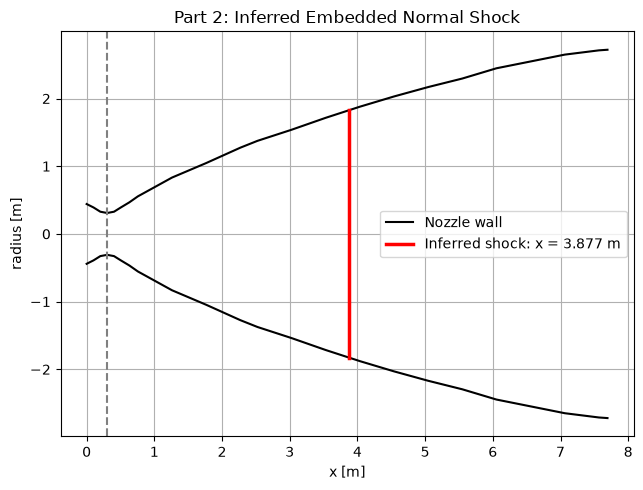

In [31]:
# Part 2: Nozzle geometry with embedded normal shock

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(x, r, color="black", label="Nozzle wall")
ax.plot(x, -r, color="black")

ax.axvline(
    x[throat_index],
    color="grey",
    linestyle="--",
)

ax.plot(
    [x_shock, x_shock],
    [-r_shock, r_shock],
    color="red",
    linewidth=2.5,
    label=f"Inferred shock: x = {x_shock:.3f} m"
)

ax.set_xlabel("x [m]")
ax.set_ylabel("radius [m]")
ax.set_title("Part 2: Inferred Embedded Normal Shock")
ax.set_aspect("equal", adjustable="box")
ax.grid(True)
ax.legend()

fig.tight_layout()
plt.show()

We'll now calculate the flow immediately after the shock and downstream exit conditions. Let's find Mach after the shock
$$M_2=\sqrt{\frac{1+\frac{\gamma-1}{2}M_1^2}{\gamma M_1^2-\frac{\gamma-1}{2}}}

In [32]:
# Part 2: Mach number immediately after the embedded shock

M2_shock = np.sqrt(
    (1 + (gamma -1) / 2 * M1_shock**2)
    / (gamma * M1_shock**2 - (gamma - 1) / 2)
)

print(f"Mach before shock: {M1_shock:.6f}")
print(f"mach after shock: {M2_shock:.6f}")

Mach before shock: 4.145771
mach after shock: 0.363951


And now we will define the downstream stagnation condition and critical area. The measure Pitot pressure gives the downstream stagnation pressure and the stagnation temperature remains constant across the adiabatic shock

In [33]:
# Part 2: Downstream stagnation conditions

# Assume one internal normal shock followed by isentropic subsonic flow
# The Pitot measurement therefore gives downstream stagnation pressure

P02_part2 = P_pitot_measured

# Stagnation temperature is conserved across the adiabatic shock
T02_part2 = T0_part2

We will need the downstream critical area, $A_2^*$.

The chocked mass-flow relation gives $\dot{m} \propto P_0A^*/\sqrt{T_0}$. Since the mass flow and stagnation temperature are conserved

$$P_{01}A_1^*=P_{02}A_2^*$$

with $A_1^*=A_t$

$$A_2^*=A_t\frac{P_{01}}{P_{02}}

In [34]:
# Part 2: Effective critical area downstream of the shock

# Conserved mass flow and T0 imply P01*A1_star = P02*A2_star
# Astar2 is the reference sonic area for the downstream area-Mach relation 

Astar2 = At * P01_part2 / P02_part2

print(f"Downstream stagnation pressure: {P02_part2 / 1000:.4f} kPa")
print(f"Downstream stagnation temperature: {T02_part2:.2f} k")
print(f"Downstream critical area: {Astar2:.6f} m^2")

Downstream stagnation pressure: 50.6625 kPa
Downstream stagnation temperature: 2000.00 k
Downstream critical area: 6.000000 m^2


Astar2 is the reference sonic area associated with the downstream flow. We will now solve for the exit Mach using the downstream arae ratio.

In [35]:
# Part 2: Exit Mach for the shock-containing nozzle

AR_exit_part2_shock = Ae_part2 / Astar2

Me_part2_shock = solve_mach_from_area(
    AR_exit_part2_shock,
    gamma,
    branch="subsonic"
)

print(f"Downstream exit area ratio: {AR_exit_part2_shock:.6f}")
print(f"Exit Mach with shock: {Me_part2_shock:.6f}")

Downstream exit area ratio: 3.876000
Exit Mach with shock: 0.154764


thix makes sense since the the downstream flow is subsonic in an expanding passage. Next we will calcualte the exit temperature, pressure, and velocity using this. We will apply the isentropic relations within the region downstream of the shock

In [36]:
# Part 2: Exit conditions for the shock_containing nozzle

factor_exit_part2_shock = (
    1 + (gamma - 1) / 2 * Me_part2_shock**2
)

Te_part2_shock = (
    T02_part2 / factor_exit_part2_shock
)

pe_part2_shock = (
    P02_part2
    / factor_exit_part2_shock**(gamma / (gamma - 1))
)

Ve_part2_shock = (
    Me_part2_shock
    * np.sqrt(gamma * R * Te_part2_shock)
)

print(f"Exit temperature with shock: {Te_part2_shock:.2f} K")
print(f"Exit pressure with shock: {pe_part2_shock / 1000:.4f} kPa")
print(f"Exit velocity with shock: {Ve_part2_shock:.2f} m/s")

Exit temperature with shock: 1995.22 K
Exit pressure with shock: 49.9405 kPa
Exit velocity with shock: 147.22 m/s


Next we will verify that $\rho_e V_eA_e$ matches the flow calculated at the throat

In [37]:
# Part 2: Independent mass-conservation check

rho_exit_part2_shock = (
    pe_part2_shock / (R * Te_part2_shock)
)

mdot_exit_check = (
    rho_exit_part2_shock
    * Ve_part2_shock
    * Ae_part2
)

mass_flow_error_pct = (
    100 * abs(mdot_exit_check - mdot_part2) / mdot_part2
)

print(f"Throat mass flow: {mdot_part2:.6f} kg/s")
print(f"Exit mass flow: {mdot_exit_check:.6f} kg/s")
print(f"Mass-flow differences: {mass_flow_error_pct:.3f}%")

Throat mass flow: 226.750353 kg/s
Exit mass flow: 226.750353 kg/s
Mass-flow differences: 0.000%


The conservation of mass still holds true! We will now calculate the thrust and specific impulse for the shock-containing flow. Once again, we will use the thrust equation

In [38]:
# Part 2: Thrust for the shock-containing flow

# Formal ambient-pressure comparison: the computed exit state is held fixed
# Changing back pressure in an actual nozzle can cahnge the internal flow
# Interpret these thrust and Isp values together with that limitation
# THe inferred shock location is held fixed for these comparisons

F_momentum_part2_shock = (
    mdot_part2 * Ve_part2_shock
)

F_pressure_vac_part2_shock = (
    (pe_part2_shock - p_vacuum) * Ae_part2
)

F_pressure_sl_part2_shock = (
    (pe_part2_shock - p_sea_level) *Ae_part2
)

F_vac_part2_shock = (
    F_momentum_part2_shock
    + F_pressure_vac_part2_shock
)

F_sl_part2_shock = (
    F_momentum_part2_shock
    + F_pressure_sl_part2_shock
)

print(f"Momentum thrust: {F_momentum_part2_shock / 1000:.2f} kN")
print(f"Vacuum pressure thrust: {F_pressure_vac_part2_shock / 1000:.2f} kN")
print(f"Sea-level pressure thrust: {F_pressure_sl_part2_shock / 1000:.2f} kN")
print(f"Total vacuum thrust: {F_vac_part2_shock / 1000:.2f} kN")
print(f"total sea-level thrust: {F_sl_part2_shock / 1000:.2f} kN")

Momentum thrust: 33.38 kN
Vacuum pressure thrust: 1161.42 kN
Sea-level pressure thrust: -1195.00 kN
Total vacuum thrust: 1194.80 kN
total sea-level thrust: -1161.62 kN


we will now calculate the corresponding specific impulses

In [39]:
# Part 2: Specific impulse for the shock-containing flow

Isp_vac_part2_shock = (
    F_vac_part2_shock / (mdot_part2 * g0)
)

Isp_sl_part2_shock = (
    F_sl_part2_shock / (mdot_part2 * g0)
)

print(f"Formal vacuum Isp: {Isp_vac_part2_shock:.2f} s")
print(f"Formal sea-level Isp: {Isp_sl_part2_shock:.2f} s")

Formal vacuum Isp: 537.31 s
Formal sea-level Isp: -522.39 s
